# Ten SQL tasks and Folium analysis

In [1]:
from pathlib import Path
import sys, json, pandas as pd
root = Path.cwd()
if not (root / 'src').exists(): root = root.parent
sys.path.insert(0, str(root / 'src'))
from IPython.display import display, Image, IFrame


In [2]:
import sqlite3
from sql_lab import QUERIES
data=pd.read_csv(root/'data/raw/Spacex_SQL.csv').dropna(subset=['Date'])
for col in data.select_dtypes(include=['object','string']).columns: data[col]=data[col].str.strip()
con=sqlite3.connect(':memory:')
data.to_sql('launches',con,index=False)
print('SQL sample:',len(data),'records')

SQL sample: 101 records


In [3]:
print('01_unique_sites')
print(QUERIES['01_unique_sites'])
display(pd.read_sql_query(QUERIES['01_unique_sites'],con))

01_unique_sites
SELECT DISTINCT Launch_Site FROM launches ORDER BY Launch_Site


,Launch_Site
0,CCAFS LC-40
1,CCAFS SLC-40
2,KSC LC-39A
3,VAFB SLC-4E


In [4]:
print('02_cca_records')
print(QUERIES['02_cca_records'])
display(pd.read_sql_query(QUERIES['02_cca_records'],con))

02_cca_records
SELECT Date, Booster_Version, Launch_Site, PAYLOAD_MASS__KG_ FROM launches WHERE Launch_Site LIKE 'CCA%' ORDER BY Date LIMIT 5


,Date,Booster_Version,Launch_Site,PAYLOAD_MASS__KG_
0,2010-06-04,F9 v1.0 B0003,CCAFS LC-40,0
1,2010-12-08,F9 v1.0 B0004,CCAFS LC-40,0
2,2012-05-22,F9 v1.0 B0005,CCAFS LC-40,525
3,2012-10-08,F9 v1.0 B0006,CCAFS LC-40,500
4,2013-03-01,F9 v1.0 B0007,CCAFS LC-40,677


In [5]:
print('03_nasa_payload')
print(QUERIES['03_nasa_payload'])
display(pd.read_sql_query(QUERIES['03_nasa_payload'],con))

03_nasa_payload
SELECT Customer, SUM(PAYLOAD_MASS__KG_) AS payload_kg FROM launches WHERE Customer = 'NASA (CRS)' GROUP BY Customer


,Customer,payload_kg
0,NASA (CRS),45596


In [6]:
print('04_f9_v11_average')
print(QUERIES['04_f9_v11_average'])
display(pd.read_sql_query(QUERIES['04_f9_v11_average'],con))

04_f9_v11_average
SELECT COUNT(*) AS launches, ROUND(AVG(PAYLOAD_MASS__KG_), 2) AS mean_payload_kg FROM launches WHERE Booster_Version LIKE 'F9 v1.1%'


,launches,mean_payload_kg
0,15,2534.67


In [7]:
print('05_first_ground_landing')
print(QUERIES['05_first_ground_landing'])
display(pd.read_sql_query(QUERIES['05_first_ground_landing'],con))

05_first_ground_landing
SELECT MIN(Date) AS first_successful_ground_landing FROM launches WHERE Landing_Outcome = 'Success (ground pad)'


,first_successful_ground_landing
0,2015-12-22


In [8]:
print('06_drone_4000_6000')
print(QUERIES['06_drone_4000_6000'])
display(pd.read_sql_query(QUERIES['06_drone_4000_6000'],con))

06_drone_4000_6000
SELECT Date, Booster_Version, PAYLOAD_MASS__KG_ FROM launches WHERE Landing_Outcome = 'Success (drone ship)' AND PAYLOAD_MASS__KG_ > 4000 AND PAYLOAD_MASS__KG_ < 6000 ORDER BY Date


,Date,Booster_Version,PAYLOAD_MASS__KG_
0,2016-05-06,F9 FT B1022,4696
1,2016-08-14,F9 FT B1026,4600
2,2017-03-30,F9 FT B1021.2,5300
3,2017-10-11,F9 FT B1031.2,5200


In [9]:
print('07_mission_outcomes')
print(QUERIES['07_mission_outcomes'])
display(pd.read_sql_query(QUERIES['07_mission_outcomes'],con))

07_mission_outcomes
SELECT Mission_Outcome, COUNT(*) AS missions FROM launches GROUP BY Mission_Outcome ORDER BY missions DESC


,Mission_Outcome,missions
0,Success,99
1,Success (payload status unclear),1
2,Failure (in flight),1


In [10]:
print('08_max_payload_boosters')
print(QUERIES['08_max_payload_boosters'])
display(pd.read_sql_query(QUERIES['08_max_payload_boosters'],con))

08_max_payload_boosters
SELECT Booster_Version, PAYLOAD_MASS__KG_ FROM launches WHERE PAYLOAD_MASS__KG_ = (SELECT MAX(PAYLOAD_MASS__KG_) FROM launches) ORDER BY Date


,Booster_Version,PAYLOAD_MASS__KG_
0,F9 B5 B1048.4,15600
1,F9 B5 B1049.4,15600
2,F9 B5 B1051.3,15600
3,F9 B5 B1056.4,15600
4,F9 B5 B1048.5,15600
5,F9 B5 B1051.4,15600
6,F9 B5 B1049.5,15600
7,F9 B5 B1060.2,15600
8,F9 B5 B1058.3,15600
9,F9 B5 B1051.6,15600


In [11]:
print('09_2015_drone_failures')
print(QUERIES['09_2015_drone_failures'])
display(pd.read_sql_query(QUERIES['09_2015_drone_failures'],con))

09_2015_drone_failures
SELECT Date, substr(Date,6,2) AS month, Booster_Version, Launch_Site, Landing_Outcome FROM launches WHERE Date LIKE '2015-%' AND Landing_Outcome = 'Failure (drone ship)' ORDER BY Date


,Date,month,Booster_Version,Launch_Site,Landing_Outcome
0,2015-01-10,01,F9 v1.1 B1012,CCAFS LC-40,Failure (drone ship)
1,2015-04-14,04,F9 v1.1 B1015,CCAFS LC-40,Failure (drone ship)


In [12]:
print('10_rank_outcomes')
print(QUERIES['10_rank_outcomes'])
display(pd.read_sql_query(QUERIES['10_rank_outcomes'],con))

10_rank_outcomes
SELECT Landing_Outcome, COUNT(*) AS launches, DENSE_RANK() OVER (ORDER BY COUNT(*) DESC) AS rank FROM launches WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY launches DESC, Landing_Outcome


,Landing_Outcome,launches,rank
0,No attempt,10,1
1,Failure (drone ship),5,2
2,Success (drone ship),5,2
3,Controlled (ocean),3,3
4,Success (ground pad),3,3
5,Failure (parachute),2,4
6,Uncontrolled (ocean),2,4
7,Precluded (drone ship),1,5


In [13]:
from build_folium_map import main
geo = main()
display(pd.DataFrame(geo['sites']))

{
  "records": 56,
  "sites": [
    {
      "Launch Site": "CCAFS LC-40",
      "Lat": 28.56230197,
      "Long": -80.57735648,
      "launches": 26,
      "successes": 7
    },
    {
      "Launch Site": "CCAFS SLC-40",
      "Lat": 28.56319718,
      "Long": -80.57682003,
      "launches": 7,
      "successes": 3
    },
    {
      "Launch Site": "KSC LC-39A",
      "Lat": 28.57325457,
      "Long": -80.64689529,
      "launches": 13,
      "successes": 10
    },
    {
      "Launch Site": "VAFB SLC-4E",
      "Lat": 34.63283416,
      "Long": -120.6107455,
      "launches": 10,
      "successes": 4
    }
  ],
  "coastline_point": [
    28.56268,
    -80.56789
  ],
  "launch_pad": [
    28.56230197,
    -80.57735648
  ],
  "distance_km": 0.9254712159290069,
  "road_point": [
    28.56268,
    -80.57077
  ],
  "road_distance_km": 0.6446213093048845,
  "point_method": "Visual OpenStreetMap selection using Folium MousePosition, 2026-10-23"
}


,Launch Site,Lat,Long,launches,successes
0,CCAFS LC-40,28.562302,-80.577356,26,7
1,CCAFS SLC-40,28.563197,-80.576820,7,3
2,KSC LC-39A,28.573255,-80.646895,13,10
3,VAFB SLC-4E,34.632834,-120.610745,10,4


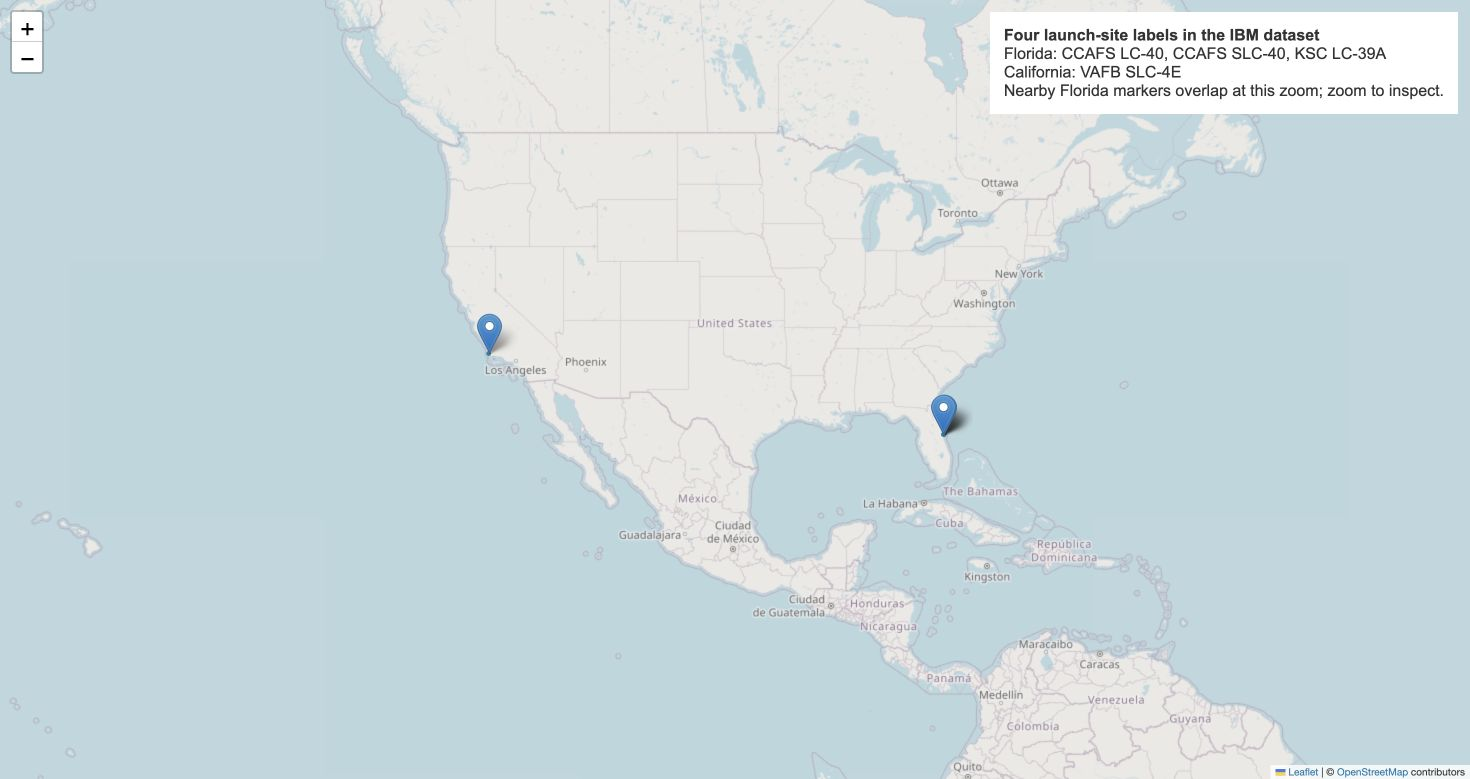

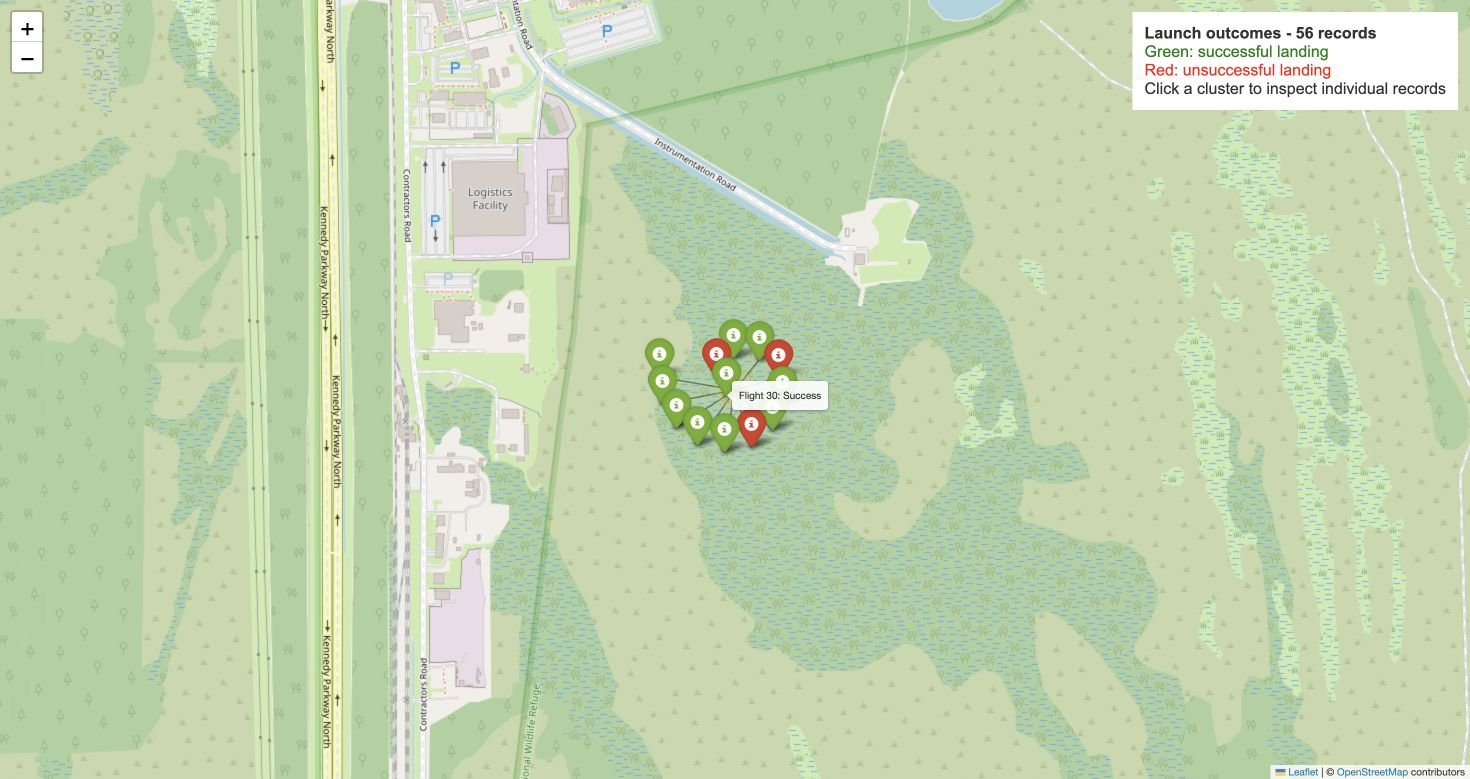

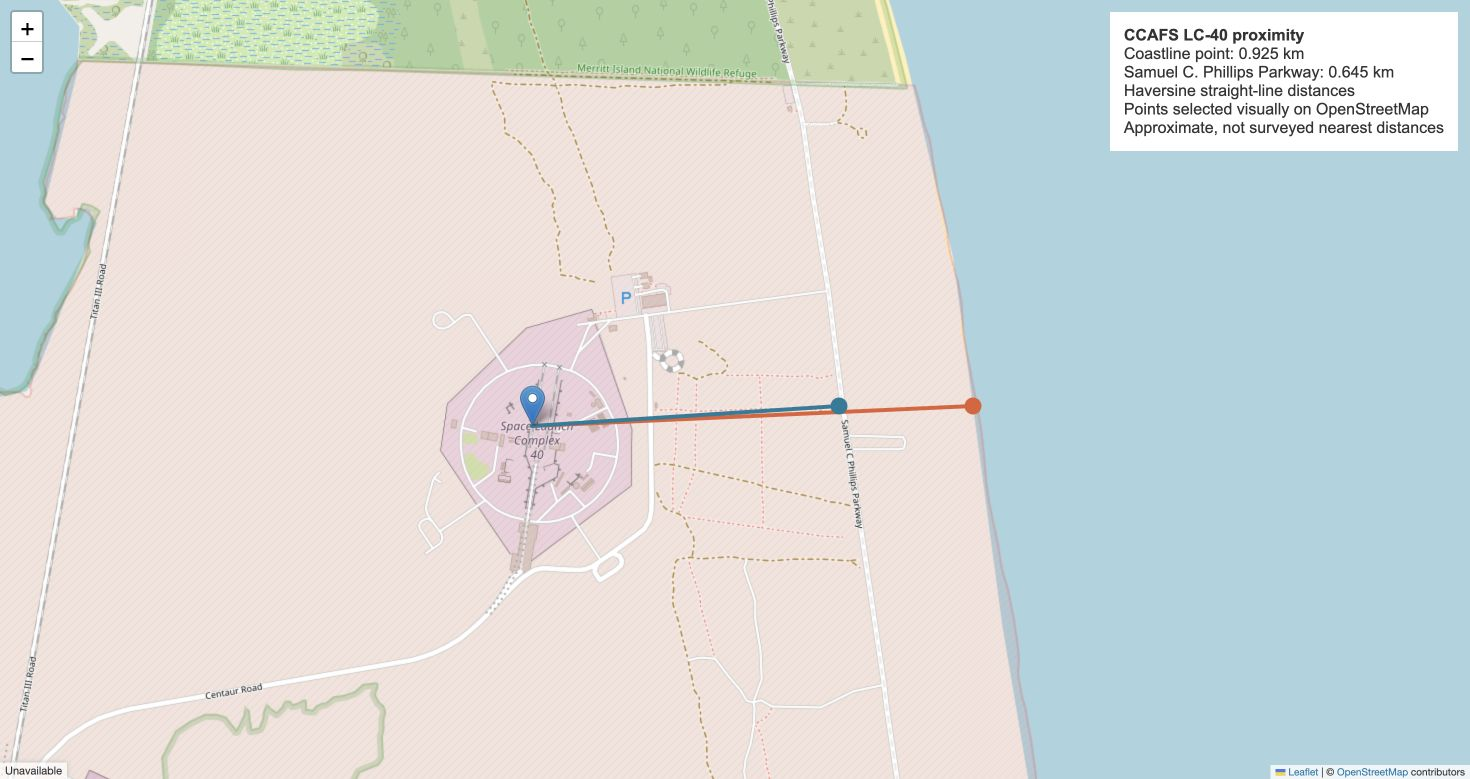

Interactive maps: outputs/launch_sites_folium.html, launch_outcomes_folium.html, launch_proximity_folium.html


In [14]:
for name in ['map_sites.png','map_outcomes.png','map_proximity.png']:
    display(Image(filename=str(root/'outputs/figures'/name)))
print('Interactive maps: outputs/launch_sites_folium.html, launch_outcomes_folium.html, launch_proximity_folium.html')